# 3. Writing the two functions

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 2; integration by parts

To use the Onsager principle one has to write two functions: the free energy $A$ and
the dissipation function $\Phi$. This chapter is about how. It collects the
expressions that soft-matter problems use again and again, introduces the one piece
of mathematics needed when the variables are fields (the functional derivative), and
shows how to handle rates that are not independent (Lagrange multipliers). It ends
with a first complete calculation of the kind that fills Part II: a liquid film
squeezed between two plates.

The checks are a numerical derivative of a discretised free energy, the exponential
relaxation of two connected reservoirs, and the closed-form solution for the squeeze
film.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 3.1 Free energies

The free energy is an equilibrium quantity. It is found from thermodynamics and
statistical mechanics, with no reference to how the system moves, and it is usually
the easier of the two functions. The contributions that appear in this book are:

| Contribution | Expression | Used in |
|---|---|---|
| Gravity | $\int \rho g z\,dV$ | capillary rise, sedimentation |
| Interfaces | $\gamma\times(\text{area})$, summed over the interfaces | capillary rise, droplets, coalescence |
| Mixing, dilute solution | $k_BT\int c\,(\ln c - 1)\,dV$ | diffusion |
| Mixing, general | $\int f(c)\,dV$, with osmotic pressure $\Pi = c f' - f$ | sedimentation, gels |
| Concentration gradients | $\int \tfrac12\kappa\,\lvert\nabla c\rvert^2\,dV$ | phase separation |
| Elasticity of a network | $\int \tfrac12 G\,(\lambda_1^2 + \lambda_2^2 + \lambda_3^2 - 3)\,dV$ | gels |
| External potential | $\int c\,U(\mathbf r)\,dV$ | traps, fields |

Here $c$ is a number density, $\gamma$ an interfacial tension, $G$ a shear modulus and
$\lambda_i$ the principal stretches. Two conventions are implied. In $\ln c$ the
concentration is measured in units of a fixed reference concentration; changing
the reference adds a term proportional to the number of particles, which is
conserved and has no effect on the motion. The elastic energy is per unit volume of
the undeformed network. If the system exchanges matter or volume with a
reservoir, the energy of the reservoir is part of $A$: the term $-GQ$ in Chapter 1
was the rate of change of the energy of whatever maintained the pressure gradient.

## 3.2 Dissipation functions

The dissipation function is half the rate at which the motion turns work into heat.
It depends on the mechanism of friction, and writing it requires a picture of the
flow. Four mechanisms cover most of soft matter.

| Mechanism | Dissipation function $\Phi$ |
|---|---|
| Viscous flow of a liquid | $\dfrac{\eta}{4}\displaystyle\int \sum_{i,j}\Big(\dfrac{\partial v_i}{\partial x_j} + \dfrac{\partial v_j}{\partial x_i}\Big)^2 dV$ |
| Particles moving through a solvent | $\dfrac12\displaystyle\int \zeta\,c\,\lvert\mathbf v_p - \mathbf v_s\rvert^2\,dV$ |
| Solvent moving through a network or porous solid | $\dfrac12\displaystyle\int \xi\,\lvert\mathbf v_s - \mathbf v_n\rvert^2\,dV$, with $\xi = \eta/\kappa$ ($\kappa$: permeability) |
| A moving contact line | $\dfrac12\,\xi_{\rm cl}\,\dot R^2 \times(\text{length of the line})$ |

In thin films and narrow tubes the velocity profile across the gap is fixed by the
walls, and the viscous dissipation can be integrated across the gap once and for
all. The result is a friction on the *mean* velocity $\bar v$:

| Geometry | Velocity profile | $\Phi$ |
|---|---|---|
| Film of thickness $h$ on a solid, free surface | half parabola | $\dfrac12\displaystyle\int \dfrac{3\eta}{h}\,\bar v^2\,dS$ |
| Gap of width $h$ between two solid walls | parabola | $\dfrac12\displaystyle\int \dfrac{12\eta}{h}\,\bar v^2\,dS$ |
| Tube of circular section, any radius | parabola | $\dfrac12\displaystyle\int 8\pi\eta\,\bar v^2\,dz$ |

The three coefficients are worth deriving once. In each case the profile is the
quadratic that satisfies the boundary conditions and has the given mean, and the
coefficient is $\int\eta\,(du/dz)^2$ across the section.

In [2]:
z, h, vbar, eta, a, r = sp.symbols("z h vbar eta a r", positive=True)
c1, c2 = sp.symbols("c1 c2")

# film on a solid wall with a free surface: u(0) = 0, u'(h) = 0
u = c1 * z + c2 * z**2
s = sp.solve([sp.diff(u, z).subs(z, h), sp.integrate(u, (z, 0, h)) / h - vbar], [c1, c2])
u_film = sp.factor(u.subs(s))
print("free film:  u =", u_film, "   2 Phi per area =", sp.simplify(sp.integrate(eta * sp.diff(u_film, z) ** 2, (z, 0, h))))

# gap between two walls: u(0) = u(h) = 0
s = sp.solve([u.subs(z, h), sp.integrate(u, (z, 0, h)) / h - vbar], [c1, c2])
u_gap = sp.factor(u.subs(s))
print("gap:        u =", u_gap, "   2 Phi per area =", sp.simplify(sp.integrate(eta * sp.diff(u_gap, z) ** 2, (z, 0, h))))

# circular tube of radius a: u(a) = 0
u_tube = 2 * vbar * (1 - r**2 / a**2)
assert sp.simplify(sp.integrate(u_tube * 2 * sp.pi * r, (r, 0, a)) / (sp.pi * a**2) - vbar) == 0
print("tube:       u =", u_tube, "   2 Phi per length =",
      sp.simplify(sp.integrate(eta * sp.diff(u_tube, r) ** 2 * 2 * sp.pi * r, (r, 0, a))))

free film:  u = -3*vbar*z*(-2*h + z)/(2*h**2)    2 Phi per area = 3*eta*vbar**2/h
gap:        u = -6*vbar*z*(-h + z)/h**2    2 Phi per area = 12*eta*vbar**2/h
tube:       u = 2*vbar*(1 - r**2/a**2)    2 Phi per length = 8*pi*eta*vbar**2


The outputs are the rates of dissipation, $2\Phi$: $3\eta\bar v^2/h$, $12\eta\bar v^2/h$
and $8\pi\eta\bar v^2$. The last does not contain the radius of the tube. These three
numbers are all the hydrodynamics needed for most of Part II.

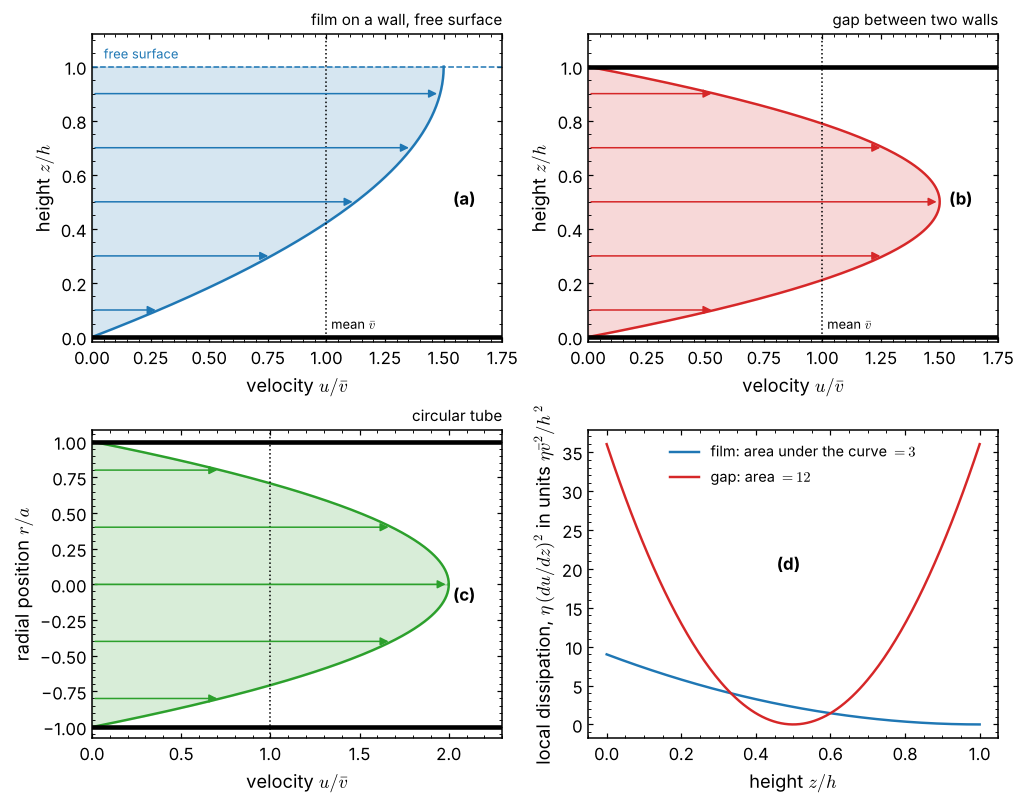

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))
s_ = np.linspace(0, 1, 200)
profiles_ = {
    "film": (3 * (s_ - s_**2 / 2), 9 * (1 - s_) ** 2, "film on a wall, free surface", "C0"),
    "gap": (6 * s_ * (1 - s_), 36 * (1 - 2 * s_) ** 2, "gap between two walls", "C3"),
}
for ax, key, lab in ((axes[0, 0], "film", "(a)"), (axes[0, 1], "gap", "(b)")):
    uu, _, title, col = profiles_[key]
    ax.fill_betweenx(s_, 0, uu, color=col, alpha=0.18)
    ax.plot(uu, s_, color=col)
    for zz in np.linspace(0.1, 0.9, 5):
        ax.annotate("", xy=(np.interp(zz, s_, uu), zz), xytext=(0, zz), arrowprops=dict(arrowstyle="-|>", color=col, lw=1))
    ax.axvline(1, color="k", ls=":", lw=1); ax.text(1.02, 0.03, r"mean $\bar v$", fontsize=8.5)
    ax.axhline(0, color="k", lw=3)
    if key == "gap":
        ax.axhline(1, color="k", lw=3)
    else:
        ax.axhline(1, color=col, lw=1, ls="--"); ax.text(0.05, 1.03, "free surface", fontsize=8.5, color=col)
    ax.set_xlim(0, 1.75); ax.set_ylim(-0.02, 1.12)
    ax.set_xlabel(r"velocity $u/\bar v$"); ax.set_ylabel("height $z/h$"); ax.set_title(title, loc="right", fontsize=10)
    on.panel_label(ax, lab, x=0.88, y=0.5)

ax = axes[1, 0]
uu = 2 * (1 - s_**2)
ax.fill_betweenx(s_, 0, uu, color="C2", alpha=0.18); ax.fill_betweenx(-s_, 0, uu, color="C2", alpha=0.18)
ax.plot(uu, s_, color="C2"); ax.plot(uu, -s_, color="C2")
for zz in np.linspace(-0.8, 0.8, 5):
    ax.annotate("", xy=(2 * (1 - zz**2), zz), xytext=(0, zz), arrowprops=dict(arrowstyle="-|>", color="C2", lw=1))
ax.axhline(1, color="k", lw=3); ax.axhline(-1, color="k", lw=3); ax.axvline(1, color="k", ls=":", lw=1)
ax.set_xlim(0, 2.3); ax.set_ylim(-1.08, 1.08)
ax.set_xlabel(r"velocity $u/\bar v$"); ax.set_ylabel("radial position $r/a$"); ax.set_title("circular tube", loc="right", fontsize=10)
on.panel_label(ax, "(c)", x=0.88, y=0.5)

ax = axes[1, 1]
ax.plot(s_, profiles_["film"][1], color="C0", label=r"film: area under the curve $= 3$")
ax.plot(s_, profiles_["gap"][1], color="C3", label=r"gap: area $= 12$")
ax.set_xlabel("height $z/h$"); ax.set_ylabel(r"local dissipation, $\eta\,(du/dz)^2$ in units $\eta\bar v^2/h^2$")
ax.legend(loc="upper center"); on.panel_label(ax, "(d)", x=0.46, y=0.6)
plt.show()

**Figure 3.1.** Velocity profiles that carry the same mean velocity $\bar v$ in the
three standard geometries: **(a)** a film on a wall with a free surface, **(b)** a gap
between two walls, **(c)** a circular tube. **(d)** Where the energy is dissipated:
at the walls, where the shear is largest, and not at all at a free surface or on
the midplane of a gap. A second wall quadruples the dissipation for the same
flow, which is the difference between $3\eta/h$ and $12\eta/h$.

## 3.3 Fields and the functional derivative

When the state is a field $c(x)$, the free energy is a *functional*: a rule that
assigns a number to a whole function. A typical one is

$$ A[c] = \int \Big[ f(c) + \frac{\kappa}{2}\Big(\frac{dc}{dx}\Big)^2 \Big]\,dx . \tag{3.1} $$

The Rayleighian needs $\dot A$, the rate of change of $A$ when the field changes at
the rate $\dot c(x)$. For a function of several variables this would be
$\sum_i (\partial A/\partial x_i)\dot x_i$. The same holds here, with the sum replaced
by an integral.

Change the field to $c + \delta c$, with $\delta c$ small and zero at the ends (or
periodic, as in the check below), and keep the first order:

$$ \delta A = \int \Big[ f'(c)\,\delta c + \kappa\,\frac{dc}{dx}\frac{d\,\delta c}{dx} \Big]dx
            = \int \Big[ f'(c) - \kappa\,\frac{d^2c}{dx^2} \Big]\,\delta c\;dx . $$

The second step is an integration by parts. The quantity in brackets multiplies the
change of the field at each point; it is called the **functional derivative** of
$A$ and written $\delta A/\delta c$:

$$ \frac{\delta A}{\delta c} = f'(c) - \kappa\,\frac{d^2c}{dx^2} ,
   \qquad \dot A = \int \frac{\delta A}{\delta c}\,\dot c\;dx . \tag{3.2} $$

For a free energy of this type it is the chemical potential. In general, for
$A = \int a(c, c')\,dx$ with $c' = dc/dx$,

$$ \frac{\delta A}{\delta c} = \frac{\partial a}{\partial c} - \frac{d}{dx}\frac{\partial a}{\partial c'} . $$

The functional derivative is an ordinary derivative in disguise. Divide the $x$ axis
into cells of width $\Delta x$ and let $c_i$ be the value in cell $i$. Then $A$ is a
function of the numbers $c_1, \dots, c_N$, and comparing $\delta A = \sum_i
(\partial A/\partial c_i)\,\delta c_i$ with Eq. (3.2) gives

$$ \frac{\delta A}{\delta c}(x_i) \approx \frac{1}{\Delta x}\frac{\partial A}{\partial c_i} . $$

The cell below checks Eq. (3.2) in this way, for the free energy of a binary mixture,
$f(c) = c\ln c + (1 - c)\ln(1 - c) + \chi\,c(1 - c)$, on a periodic interval. Each
$\partial A/\partial c_i$ is computed by changing one $c_i$ slightly and recomputing
the sum.

In [4]:
chi, kappa = 2.5, 2e-3
f = lambda c: c * np.log(c) + (1 - c) * np.log(1 - c) + chi * c * (1 - c)
df = lambda c: np.log(c / (1 - c)) + chi * (1 - 2 * c)
field = lambda x: 0.5 + 0.2 * np.sin(2 * np.pi * x) + 0.1 * np.cos(4 * np.pi * x)
d2field = lambda x: -0.2 * (2 * np.pi) ** 2 * np.sin(2 * np.pi * x) - 0.1 * (4 * np.pi) ** 2 * np.cos(4 * np.pi * x)


def discrete_A(c, dx):
    """The sum that approximates Eq. (3.1) on a periodic grid."""
    grad = (np.roll(c, -1) - c) / dx
    return np.sum(f(c) + 0.5 * kappa * grad**2) * dx


def derivative_by_differences(N, eps=1e-6):
    x = np.arange(N) / N
    dx = 1.0 / N
    c = field(x)
    out = np.empty(N)
    for i in range(N):
        up, down = c.copy(), c.copy()
        up[i] += eps; down[i] -= eps
        out[i] = (discrete_A(up, dx) - discrete_A(down, dx)) / (2 * eps * dx)
    return x, out


exact_fd = lambda x: df(field(x)) - kappa * d2field(x)
Ns = np.array([25, 50, 100, 200, 400])
err_fd = []
for N in Ns:
    xg, num = derivative_by_differences(N)
    err_fd.append(on.sup_error(num, exact_fd(xg)))
slope, _ = on.loglog_slope(1 / Ns, err_fd)
print("  N     largest difference from Eq. (3.2)")
for N, e in zip(Ns, err_fd):
    print(f" {N:4d}    {e:.2e}")
print(f"slope against the cell width: {slope:.2f}  (2 expected for this discretisation)")
x_fd, num_fd = derivative_by_differences(50)

  N     largest difference from Eq. (3.2)
   25    7.37e-04
   50    1.85e-04
  100    4.67e-05
  200    1.17e-05
  400    2.92e-06
slope against the cell width: 1.99  (2 expected for this discretisation)


The two agree, and the difference falls as $\Delta x^2$, which is the accuracy of
the difference formula used for the gradient. A functional derivative is what a
partial derivative becomes when the variables are labelled by a continuous index.

## 3.4 Constraints

Rates are often not independent. A liquid is incompressible, so what leaves one
place must arrive at another. There are two ways to deal with this.

**Elimination.** Use the constraint to express some rates through the others, and
minimise over the independent ones.

**Lagrange multipliers.** Keep all the rates, and for each constraint
$g_k(\dot x) = 0$ add a term $-\lambda_k g_k$ to the Rayleighian. Minimise with respect
to the rates as if they were independent, then choose the multipliers $\lambda_k$ so
that the constraints hold.

The two give the same motion. The second gives something more: the multiplier has a
physical meaning. It is the force that enforces the constraint. For
incompressibility, it is the pressure.

*Example: two connected reservoirs.* Two vertical vessels of cross-sections $S_1$
and $S_2$ hold a liquid of density $\rho$ to heights $h_1$ and $h_2$. A narrow tube
of length $L$ and radius $a$ joins them at the bottom. The gravitational energy is

$$ A = \tfrac12\rho g\,\big(S_1h_1^2 + S_2h_2^2\big) , $$

and the dissipation is in the tube. With the flow rate $Q = \pi a^2\bar v$ from
vessel 1 to vessel 2, the last row of the second table of Section 3.2 gives

$$ \Phi = \tfrac12\cdot 8\pi\eta\,\bar v^2 L = \tfrac12 R_h Q^2 , \qquad R_h = \frac{8\eta L}{\pi a^4} . $$

There are three rates, $\dot h_1$, $\dot h_2$ and $Q$, and two constraints,

$$ S_1\dot h_1 + Q = 0 , \qquad S_2\dot h_2 - Q = 0 . $$

With multipliers $p_1$ and $p_2$, the function to minimise is

$$ \Phi + \dot A - p_1\big(S_1\dot h_1 + Q\big) - p_2\big(S_2\dot h_2 - Q\big) . $$

`on.kinetic_equations` accepts constraints and multipliers:

In [5]:
h1, h2, q = sp.symbols("h1 h2 q")                     # q: a dummy variable whose rate is Q
hd1, hd2, Q, p1, p2 = sp.symbols("hdot1 hdot2 Q p1 p2")
S1, S2, rhog, Rh = sp.symbols("S1 S2 rho_g R_h", positive=True)

A_res = rhog * (S1 * h1**2 + S2 * h2**2) / 2
Phi_res = Rh * Q**2 / 2

with_multipliers = on.kinetic_equations(A_res, Phi_res, [h1, h2, q], [hd1, hd2, Q],
                                        constraints=[S1 * hd1 + Q, S2 * hd2 - Q], multipliers=[p1, p2])
for key in (p1, p2, Q, hd1, hd2):
    print(f"{str(key):6s} =", with_multipliers[key])

# elimination: one independent rate, hdot1;  Q = -S1 hdot1,  h2 = (V - S1 h1) / S2
V = sp.symbols("V", positive=True)
h2_of_h1 = (V - S1 * h1) / S2
eliminated = on.kinetic_equations(A_res.subs(h2, h2_of_h1), Rh * (S1 * hd1) ** 2 / 2, [h1], [hd1])
print("\nby elimination: hdot1 =", sp.factor(eliminated[hd1]))
print("difference from the multiplier result:",
      sp.simplify(eliminated[hd1] - with_multipliers[hd1].subs(h2, h2_of_h1)))

p1     = h1*rho_g
p2     = h2*rho_g
Q      = rho_g*(h1 - h2)/R_h
hdot1  = rho_g*(-h1 + h2)/(R_h*S1)
hdot2  = rho_g*(h1 - h2)/(R_h*S2)

by elimination: hdot1 = -rho_g*(S1*h1 + S2*h1 - V)/(R_h*S1*S2)
difference from the multiplier result: 0


The multipliers come out as $p_1 = \rho g h_1$ and $p_2 = \rho g h_2$: the hydrostatic
pressures at the two ends of the tube. Nobody put hydrostatics into the calculation.
The flow rate is $Q = (p_1 - p_2)/R_h$, which is Poiseuille's law, and elimination
gives the same $\dot h_1$.

The difference of the heights then obeys $d(h_1 - h_2)/dt = -(h_1 - h_2)/\tau$ with
$\tau = R_h S_1S_2/[\rho g(S_1 + S_2)]$, an exponential relaxation, which the next
cell checks against a numerical integration of the kinetic equations.

In [6]:
vals = {S1: 1.0, S2: 3.0, rhog: 1.0, Rh: 2.0}
rhs_res = on.rate_function(with_multipliers, [h1, h2], [hd1, hd2], vals)
t_res = np.linspace(0, 8, 161)
res = solve_ivp(rhs_res, (0, 8), [2.0, 0.4], t_eval=t_res, rtol=1e-11, atol=1e-13)
tau = 2.0 * 1.0 * 3.0 / (1.0 * (1.0 + 3.0))
h_final = (1.0 * 2.0 + 3.0 * 0.4) / 4.0
h1_exact = h_final + (2.0 - h_final) * np.exp(-t_res / tau)
h2_exact = h_final + (0.4 - h_final) * np.exp(-t_res / tau)
print(f"relaxation time tau = {tau:.2f},  final height = {h_final:.2f}")
print(f"largest difference from the exponential solution: {max(on.sup_error(res.y[0], h1_exact), on.sup_error(res.y[1], h2_exact)):.1e}")

relaxation time tau = 1.50,  final height = 0.80
largest difference from the exponential solution: 3.1e-12


## 3.5 A complete example: the squeeze film

A circular plate of radius $R$ is pressed with a force $F$ towards a parallel wall,
with a viscous liquid in the gap of width $h(t) \ll R$. How fast does the gap close?

*Variable.* One: the gap $h$.

*Kinematics.* The liquid is incompressible, so the liquid displaced by the plate
inside a circle of radius $r$ must cross that circle: $2\pi r h\,\bar v(r) = -\pi
r^2\dot h$. The mean radial velocity is therefore fixed by $\dot h$,

$$ \bar v(r) = -\frac{r\,\dot h}{2h} . $$

Here the constraint has been used by elimination: it leaves no freedom in the mean
velocity.

*Free energy.* The plate is pushed by the force $F$, so $A = Fh$ and $\dot A = F\dot h$.

*Dissipation function.* The gap is narrow and the flow is radial between two walls;
the second row of the same table gives

$$ \Phi = \frac12\int_0^R \frac{12\eta}{h}\,\bar v^2\;2\pi r\,dr = \frac{3\pi\eta R^4}{4h^3}\,\dot h^2 . $$

*Minimise.* $\partial(\Phi + \dot A)/\partial\dot h = 0$ gives

$$ \frac{3\pi\eta R^4}{2h^3}\,\dot h = -F . \tag{3.3} $$

This is Stefan's law for the force needed to squeeze (or separate) two plates. The
friction constant of the gap, $3\pi\eta R^4/2h^3$, grows without limit as the gap
closes. Integrating,

$$ \frac{1}{h^2} = \frac{1}{h_0^2} + \frac{4Ft}{3\pi\eta R^4} , \tag{3.4} $$

so that at long times $h \propto t^{-1/2}$: the plates never touch in a finite time.
The cell repeats the calculation symbolically and compares the numerical solution
of Eq. (3.3) with Eq. (3.4).

In [7]:
hh, hdot, rr = sp.symbols("h hdot r")
Fs, Rs, etas = sp.symbols("F R eta", positive=True)

vbar_r = -rr * hdot / (2 * hh)
Phi_sq = sp.integrate(sp.Rational(1, 2) * 12 * etas / hh * vbar_r**2 * 2 * sp.pi * rr, (rr, 0, Rs))
print("Phi =", Phi_sq)
squeeze = on.kinetic_equations(Fs * hh, Phi_sq, [hh], [hdot])
print("hdot =", squeeze[hdot])

rhs_sq = on.rate_function(squeeze, [hh], [hdot], {Fs: 1.0, Rs: 1.0, etas: 1.0})
t_sq = np.logspace(-1, 5, 121)
sq = solve_ivp(rhs_sq, (0, t_sq[-1]), [0.1], t_eval=t_sq, rtol=1e-11, atol=1e-14)
h_closed = 1 / np.sqrt(1 / 0.1**2 + 4 * t_sq / (3 * np.pi))
print(f"largest relative difference from Eq. (3.4): {np.max(np.abs(sq.y[0] / h_closed - 1)):.1e}")

Phi = 3*pi*R**4*eta*hdot**2/(4*h**3)
hdot = -2*F*h**3/(3*pi*R**4*eta)
largest relative difference from Eq. (3.4): 1.3e-11


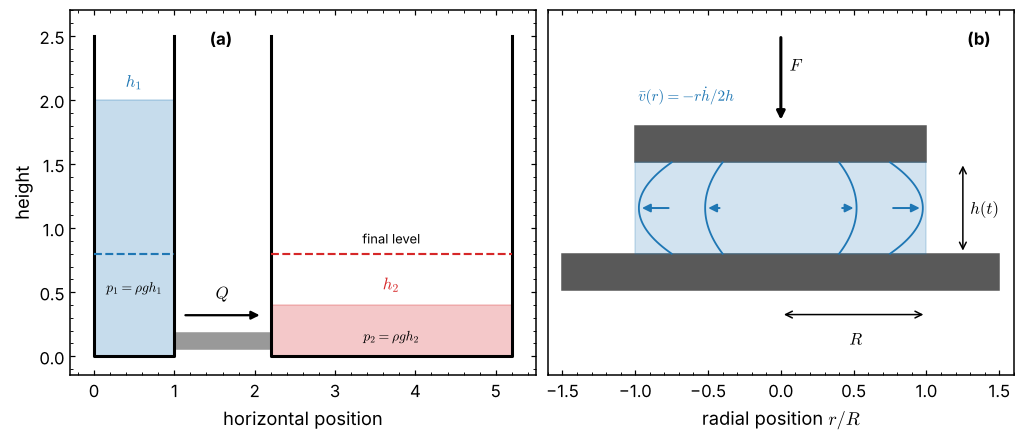

In [8]:
from matplotlib.patches import Rectangle

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

# two reservoirs joined by a tube
for x0_, wdt, hh0, hhf, col in ((0.0, 1.0, 2.0, h_final, "C0"), (2.2, 3.0, 0.4, h_final, "C3")):
    ax1.add_patch(Rectangle((x0_, 0), wdt, hh0, color=col, alpha=0.25))
    ax1.plot([x0_, x0_, x0_ + wdt, x0_ + wdt], [2.5, 0, 0, 2.5], "k-", lw=2)
    ax1.plot([x0_, x0_ + wdt], [hhf, hhf], "--", color=col, lw=1.4)
ax1.add_patch(Rectangle((1.0, 0.06), 1.2, 0.12, color="0.6"))
ax1.annotate("", xy=(2.1, 0.32), xytext=(1.1, 0.32), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
ax1.text(1.6, 0.45, "$Q$", ha="center")
ax1.text(0.5, 2.1, "$h_1$", ha="center", color="C0"); ax1.text(3.7, 0.52, "$h_2$", ha="center", color="C3")
ax1.text(0.5, 0.5, r"$p_1 = \rho g h_1$", ha="center", fontsize=9); ax1.text(3.7, 0.12, r"$p_2 = \rho g h_2$", ha="center", fontsize=9)
ax1.text(3.7, h_final + 0.08, "final level", ha="center", fontsize=8.5)
ax1.set_xlim(-0.3, 5.5); ax1.set_ylim(-0.15, 2.7); ax1.set_xlabel("horizontal position"); ax1.set_ylabel("height")
on.panel_label(ax1, "(a)", x=0.3)

# squeeze film
ax2.add_patch(Rectangle((-1.0, 0.30), 2.0, 0.12, color="0.35"))
ax2.add_patch(Rectangle((-1.5, -0.12), 3.0, 0.12, color="0.35"))
ax2.add_patch(Rectangle((-1.0, 0.0), 2.0, 0.30, color="C0", alpha=0.2))
zz = np.linspace(0, 0.30, 40)
for rpos in (-0.75, -0.4, 0.4, 0.75):
    width = 0.3 * rpos
    ax2.plot(rpos + width * 6 * (zz / 0.30) * (1 - zz / 0.30) / 1.5, zz, color="C0", lw=1.2)
    ax2.annotate("", xy=(rpos + width, 0.15), xytext=(rpos, 0.15), arrowprops=dict(arrowstyle="-|>", color="C0", lw=1.3))
ax2.annotate("", xy=(0, 0.43), xytext=(0, 0.72), arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
ax2.text(0.06, 0.6, "$F$")
ax2.annotate("", xy=(1.25, 0.30), xytext=(1.25, 0.0), arrowprops=dict(arrowstyle="<->", color="k", lw=1)); ax2.text(1.3, 0.13, "$h(t)$")
ax2.annotate("", xy=(1.0, -0.2), xytext=(0.0, -0.2), arrowprops=dict(arrowstyle="<->", color="k", lw=1)); ax2.text(0.47, -0.3, "$R$")
ax2.text(-0.98, 0.5, r"$\bar v(r) = -r\dot h/2h$", color="C0", fontsize=10)
ax2.set_xlim(-1.6, 1.6); ax2.set_ylim(-0.4, 0.8); ax2.set_xlabel("radial position $r/R$"); ax2.set_yticks([])
on.panel_label(ax2, "(b)", x=0.9)
plt.show()

**Figure 3.2.** The two examples of this chapter. **(a)** Two reservoirs joined by a
narrow tube, at the start; the dashed lines mark the common final level. The
Lagrange multipliers of the two volume constraints are the hydrostatic pressures
at the ends of the tube. **(b)** A squeeze film (gap exaggerated). As the plate
descends the liquid is driven outwards, with a mean velocity that grows in
proportion to the distance from the axis; the dissipation is therefore
concentrated near the rim, which is why the friction grows as $R^4$.

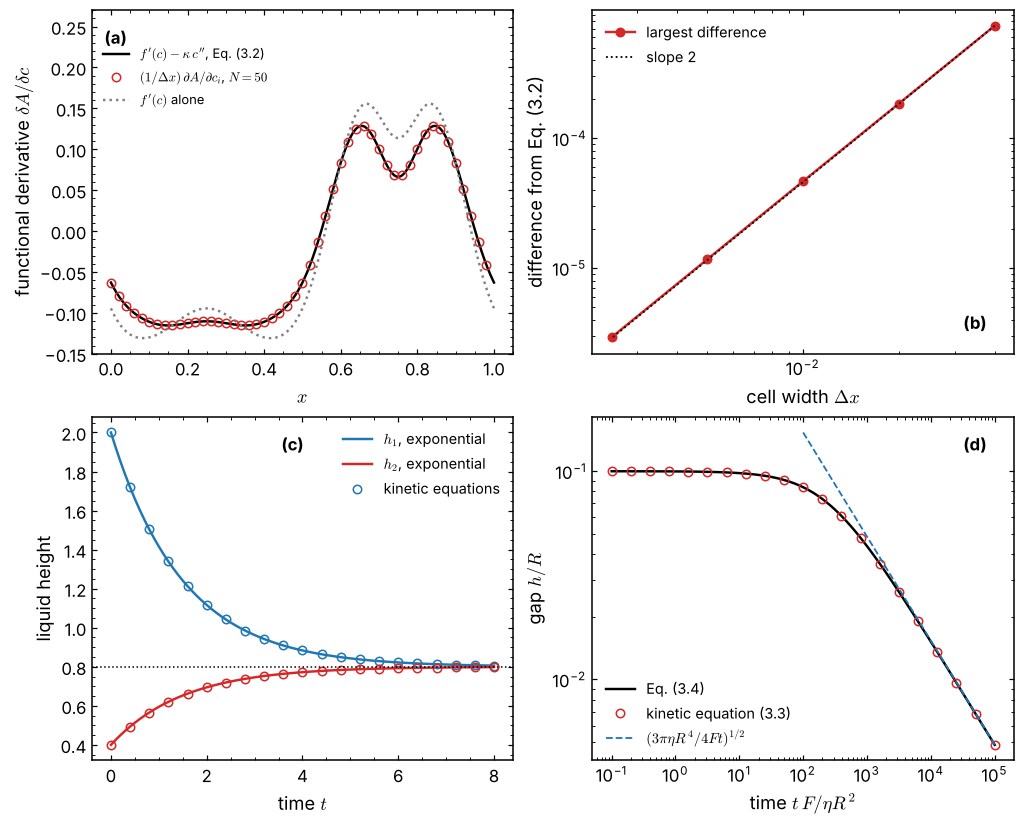

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
xs = np.linspace(0, 1, 400)
ax.plot(xs, exact_fd(xs), "k-", label=r"$f'(c) - \kappa\,c''$, Eq. (3.2)")
ax.plot(x_fd, num_fd, "o", color="C3", mfc="none", label=r"$(1/\Delta x)\,\partial A/\partial c_i$, $N = 50$")
ax.plot(xs, df(field(xs)), ":", color="0.5", label=r"$f'(c)$ alone")
ax.set_xlabel("$x$"); ax.set_ylabel(r"functional derivative $\delta A/\delta c$")
ax.set_ylim(-0.15, 0.27)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.93), fontsize=8.5); on.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.loglog(1 / Ns, err_fd, "o-", color="C3", label="largest difference")
ax.loglog(1 / Ns, err_fd[0] * (Ns[0] / Ns) ** 2, "k:", lw=1.2, label="slope 2")
ax.set_xlabel(r"cell width $\Delta x$"); ax.set_ylabel("difference from Eq. (3.2)")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(loc="upper left"); on.panel_label(ax, "(b)", x=0.88, y=0.12)

ax = axes[1, 0]
ax.plot(t_res, h1_exact, "-", color="C0", label="$h_1$, exponential")
ax.plot(t_res, h2_exact, "-", color="C3", label="$h_2$, exponential")
ax.plot(t_res[::8], res.y[0][::8], "o", color="C0", mfc="none", label="kinetic equations")
ax.plot(t_res[::8], res.y[1][::8], "o", color="C3", mfc="none")
ax.axhline(h_final, color="k", ls=":", lw=1)
ax.set_xlabel("time $t$"); ax.set_ylabel("liquid height")
ax.legend(loc="upper right"); on.panel_label(ax, "(c)", x=0.45)

ax = axes[1, 1]
ax.loglog(t_sq, h_closed, "k-", label="Eq. (3.4)")
ax.loglog(t_sq[::6], sq.y[0][::6], "o", color="C3", mfc="none", label="kinetic equation (3.3)")
ax.loglog(t_sq[60:], np.sqrt(3 * np.pi / (4 * t_sq[60:])), "--", color="C0", lw=1.2, label=r"$(3\pi\eta R^4/4Ft)^{1/2}$")
ax.set_xlabel(r"time $t\,F/\eta R^2$"); ax.set_ylabel("gap $h/R$")
ax.legend(loc="lower left"); on.panel_label(ax, "(d)", x=0.88)
plt.show()

**Figure 3.3.** **(a)** Functional derivative of the free energy (3.1) of a binary mixture:
Eq. (3.2) and the derivative of the discretised sum with respect to the value in
each cell. The dotted line omits the gradient term. **(b)** The difference falls as
the square of the cell width. **(c)** Two connected reservoirs: numerical solution
of the kinetic equations and the exponential relaxation to the common level.
**(d)** Gap of a squeeze film under a constant force: the gap closes as
$t^{-1/2}$ and never reaches zero.

## Summary

* The free energy comes from equilibrium thermodynamics. The dissipation function
  needs a picture of the motion; for thin gaps and tubes it reduces to a friction on
  the mean velocity, with coefficients $3\eta/h$, $12\eta/h$ and $8\pi\eta$.
* For a field, $\dot A = \int(\delta A/\delta c)\,\dot c\,dx$. The functional
  derivative is found by varying the field and integrating by parts; it is the
  continuum limit of $\partial A/\partial c_i$ divided by the cell width.
* Constraints among the rates are handled by elimination or by Lagrange multipliers.
  The multiplier is the force of constraint; for incompressibility it is the
  pressure.
* A complete calculation has five steps: choose the variables, relate the velocities
  to their rates, write $A$, write $\Phi$, minimise. For the squeeze film this gives
  Stefan's law in a few lines.

## Exercises

Sample solutions are in [`solutions/part1_principle/03_solutions.ipynb`](../../solutions/part1_principle/03_solutions.ipynb).

1. **A drop instead of a plate.** A drop of fixed volume $V$ is squeezed between two
   large plates by a force $F$, so that its radius grows as the gap closes,
   $\pi R^2h = V$. Neglecting surface tension, show that
   $\Phi = 3\eta V^2\dot h^2/4\pi h^5$ and that
   $h^{-4} = h_0^{-4} + 8\pi Ft/3\eta V^2$: the gap now closes as $t^{-1/4}$.
2. **Bending energy.** Find the functional derivative of
   $A = \int \tfrac12\kappa\,(d^2c/dx^2)^2\,dx$. (*Answer:* $\kappa\,d^4c/dx^4$.) Check it
   numerically by modifying `discrete_A`.
3. **Slip.** A liquid film of thickness $h$ slides on a wall with a slip length $b$,
   so that the velocity at the wall is $b\,\partial u/\partial z$. Find the velocity
   profile for a given mean velocity and show that the friction coefficient
   $3\eta/h$ becomes $3\eta/(h + 3b)$. (The dissipation now includes friction at the
   wall, $\tfrac12(\eta/b)\,u(0)^2$ per unit area.)
4. **Three vessels.** Add a third vessel connected to the second by an identical
   tube. Use `on.kinetic_equations` with three multipliers, confirm that each
   multiplier is a hydrostatic pressure, and find the two relaxation times.

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* P.-G. de Gennes, F. Brochard-Wyart and D. Quéré, *Capillarity and Wetting Phenomena* (Springer, 2004).
* L. D. Landau and E. M. Lifshitz, *Fluid Mechanics*, 2nd ed. (Pergamon, 1987).
* I. M. Gelfand and S. V. Fomin, *Calculus of Variations* (Prentice-Hall, 1963; Dover, 2000).
* L. G. Leal, *Advanced Transport Phenomena* (Cambridge University Press, 2007).

---

**Previous:** [2. Onsager's kinetic equations](02_kinetic_equations.ipynb) &nbsp;·&nbsp;
**Next:** [4. From the principle to field equations](04_field_equations.ipynb)